# Classification — Cardiotocography (CTG) Dataset

## Objective

To develop and compare machine learning classification models for predicting
the fetal state from cardiotocographic measurements.

The target variable `NSP` represents the fetal state:

- 1 — Normal
- 2 — Suspect
- 3 — Pathologic

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

%matplotlib inline

In [3]:
df = pd.read_excel(
    "../data/CTG.xls",
    sheet_name="Raw Data"
)

df.head()

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Variab10.txt,1996-12-01,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
2,Fmcs_1.txt,1996-05-03,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,1996-05-03,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,1996-05-03,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0


In [4]:
print("Shape:", df.shape)

Shape: (2130, 40)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2130 entries, 0 to 2129
Data columns (total 40 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   FileName  2126 non-null   object        
 1   Date      2126 non-null   datetime64[ns]
 2   SegFile   2126 non-null   object        
 3   b         2126 non-null   float64       
 4   e         2126 non-null   float64       
 5   LBE       2126 non-null   float64       
 6   LB        2126 non-null   float64       
 7   AC        2126 non-null   float64       
 8   FM        2127 non-null   float64       
 9   UC        2127 non-null   float64       
 10  ASTV      2127 non-null   float64       
 11  MSTV      2127 non-null   float64       
 12  ALTV      2127 non-null   float64       
 13  MLTV      2127 non-null   float64       
 14  DL        2128 non-null   float64       
 15  DS        2128 non-null   float64       
 16  DP        2128 non-null   float64       
 17  DR        2128

In [6]:
df.describe()

,Date,b,e,LBE,LB,AC,FM,UC,ASTV,MSTV,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
count,2126,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2127.000000,2127.000000,2127.000000,2127.000000,...,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000
mean,1996-04-22 16:59:22.746942592,878.439793,1702.877234,133.303857,133.303857,2.722484,7.503056,3.669017,47.008933,1.335449,...,0.024929,0.038100,0.033866,0.156162,0.118532,0.050329,0.032455,0.092662,4.509878,1.304327
min,1980-01-04 00:00:00,0.000000,287.000000,106.000000,106.000000,0.000000,0.000000,0.000000,12.000000,0.200000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,1996-05-02 00:00:00,55.000000,1009.000000,126.000000,126.000000,0.000000,0.000000,1.000000,32.000000,0.700000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000
50%,1996-08-21 00:00:00,538.000000,1241.000000,133.000000,133.000000,1.000000,0.000000,3.000000,49.000000,1.200000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,1.000000
75%,1997-03-20 00:00:00,1521.000000,2434.750000,140.000000,140.000000,4.000000,2.000000,5.000000,61.000000,1.700000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.000000,1.000000
max,1998-06-06 00:00:00,3296.000000,3599.000000,160.000000,160.000000,26.000000,564.000000,23.000000,87.000000,7.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,10.000000,3.000000
std,NaN,894.084748,930.919143,9.840844,9.840844,3.560850,39.030452,2.877148,17.210648,0.891543,...,0.155947,0.191482,0.180928,0.363094,0.323314,0.218675,0.177248,0.290027,3.026883,0.614377


In [7]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

FileName    4
Date        4
SegFile     4
b           4
e           4
LBE         4
LB          4
AC          4
FM          3
UC          3
ASTV        3
MSTV        3
ALTV        3
MLTV        3
DL          2
DS          2
DP          2
DR          2
Width       4
Min         4
Max         4
Nmax        4
Nzeros      4
Mode        4
Mean        4
Median      4
Variance    4
Tendency    4
A           4
B           4
C           4
D           4
E           4
AD          4
DE          4
LD          4
FS          4
SUSP        4
CLASS       4
NSP         4
dtype: int64

In [8]:
df.isnull().sum()

FileName    4
Date        4
SegFile     4
b           4
e           4
LBE         4
LB          4
AC          4
FM          3
UC          3
ASTV        3
MSTV        3
ALTV        3
MLTV        3
DL          2
DS          2
DP          2
DR          2
Width       4
Min         4
Max         4
Nmax        4
Nzeros      4
Mode        4
Mean        4
Median      4
Variance    4
Tendency    4
A           4
B           4
C           4
D           4
E           4
AD          4
DE          4
LD          4
FS          4
SUSP        4
CLASS       4
NSP         4
dtype: int64

In [9]:
# Remove rows where the target variable is missing
df = df.dropna(subset=["NSP"]).copy()

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:", df.isnull().sum().sum())

Shape after cleaning: (2126, 40)
Missing values after cleaning: 0


In [10]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## Data Cleaning Summary

The original CTG dataset contained 2,130 observations. A total of 146
missing cells were identified across the dataset. Four observations had
missing values in the target variable `NSP`, so these observations were
removed because they cannot be used for supervised classification.

After removing these incomplete observations, 2,126 observations remained.
A duplicate-row check found no duplicate observations, and no missing
values remained in the cleaned dataset.

## Target Distrbution

In [11]:
target_counts = df["NSP"].value_counts().sort_index()

print(target_counts)

NSP
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64


In [12]:
target_percentages = (
    df["NSP"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(target_percentages.round(2))

NSP
1.0    77.85
2.0    13.88
3.0     8.28
Name: proportion, dtype: float64


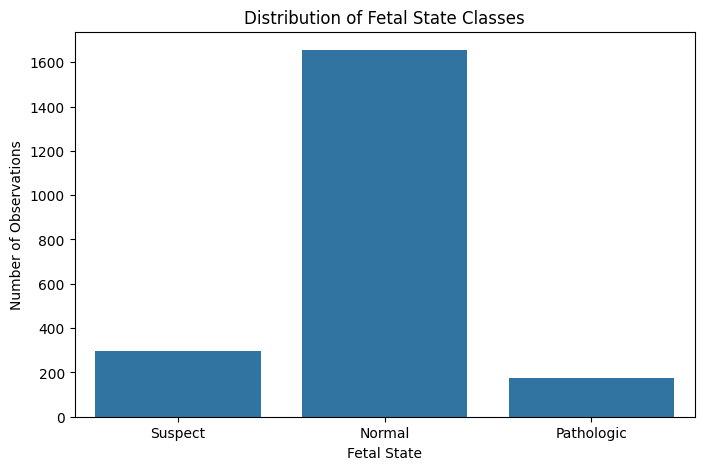

In [13]:
class_names = {
    1: "Normal",
    2: "Suspect",
    3: "Pathologic"
}

plot_df = df.copy()
plot_df["NSP_Label"] = plot_df["NSP"].map(class_names)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=plot_df,
    x="NSP_Label"
)

plt.title("Distribution of Fetal State Classes")
plt.xlabel("Fetal State")
plt.ylabel("Number of Observations")

plt.show()

## Target Variable Analysis

The target variable `NSP` represents the fetal state.

- `1` — Normal
- `2` — Suspect
- `3` — Pathologic

The cleaned dataset contains 2,126 observations. The class distribution is
imbalanced, with the Normal class containing substantially more observations
than the Suspect and Pathologic classes.

Therefore, model performance will not be evaluated using accuracy alone.
Precision, recall, F1-score, and the confusion matrix will also be considered,
with particular attention to macro-averaged F1-score.

In [14]:
feature_columns = [
    "LB",
    "AC",
    "FM",
    "UC",
    "ASTV",
    "MSTV",
    "ALTV",
    "MLTV",
    "DL",
    "DS",
    "DP",
    "Width",
    "Min",
    "Max",
    "Nmax",
    "Nzeros",
    "Mode",
    "Mean",
    "Median",
    "Variance",
    "Tendency"
]

X = df[feature_columns]
y = df["NSP"].astype(int)

print("Number of features:", X.shape[1])
print("Number of observations:", X.shape[0])

Number of features: 21
Number of observations: 2126


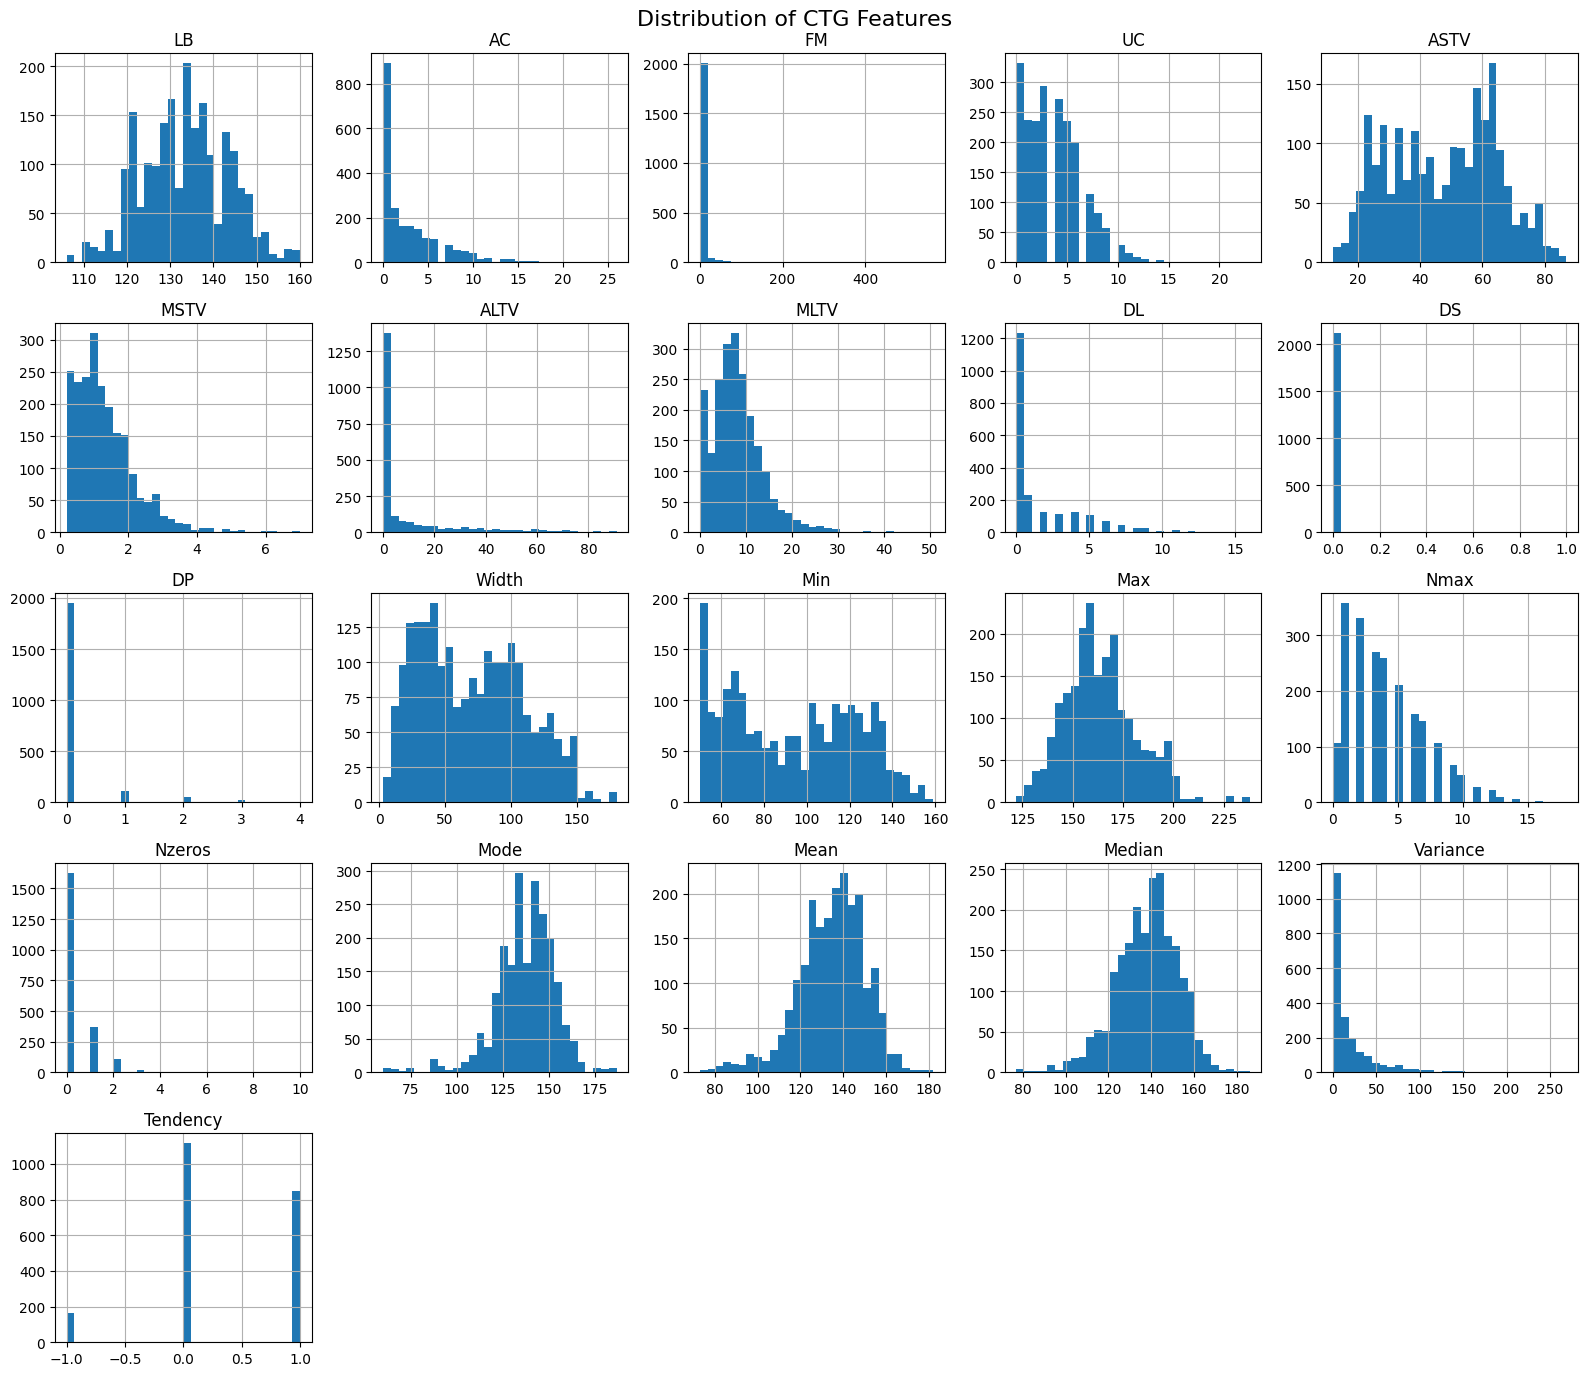

In [15]:
X.hist(
    figsize=(16, 14),
    bins=30
)

plt.suptitle("Distribution of CTG Features", fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
unique_counts = X.nunique().sort_values()

print(unique_counts)

DS            2
Tendency      3
DP            5
Nzeros        9
DL           15
Nmax         18
UC           19
AC           22
LB           48
MSTV         57
ASTV         75
Max          86
ALTV         87
Mode         88
Median       95
FM           96
Mean        103
Min         109
Variance    133
Width       154
MLTV        249
dtype: int64


## Correlation Analysis

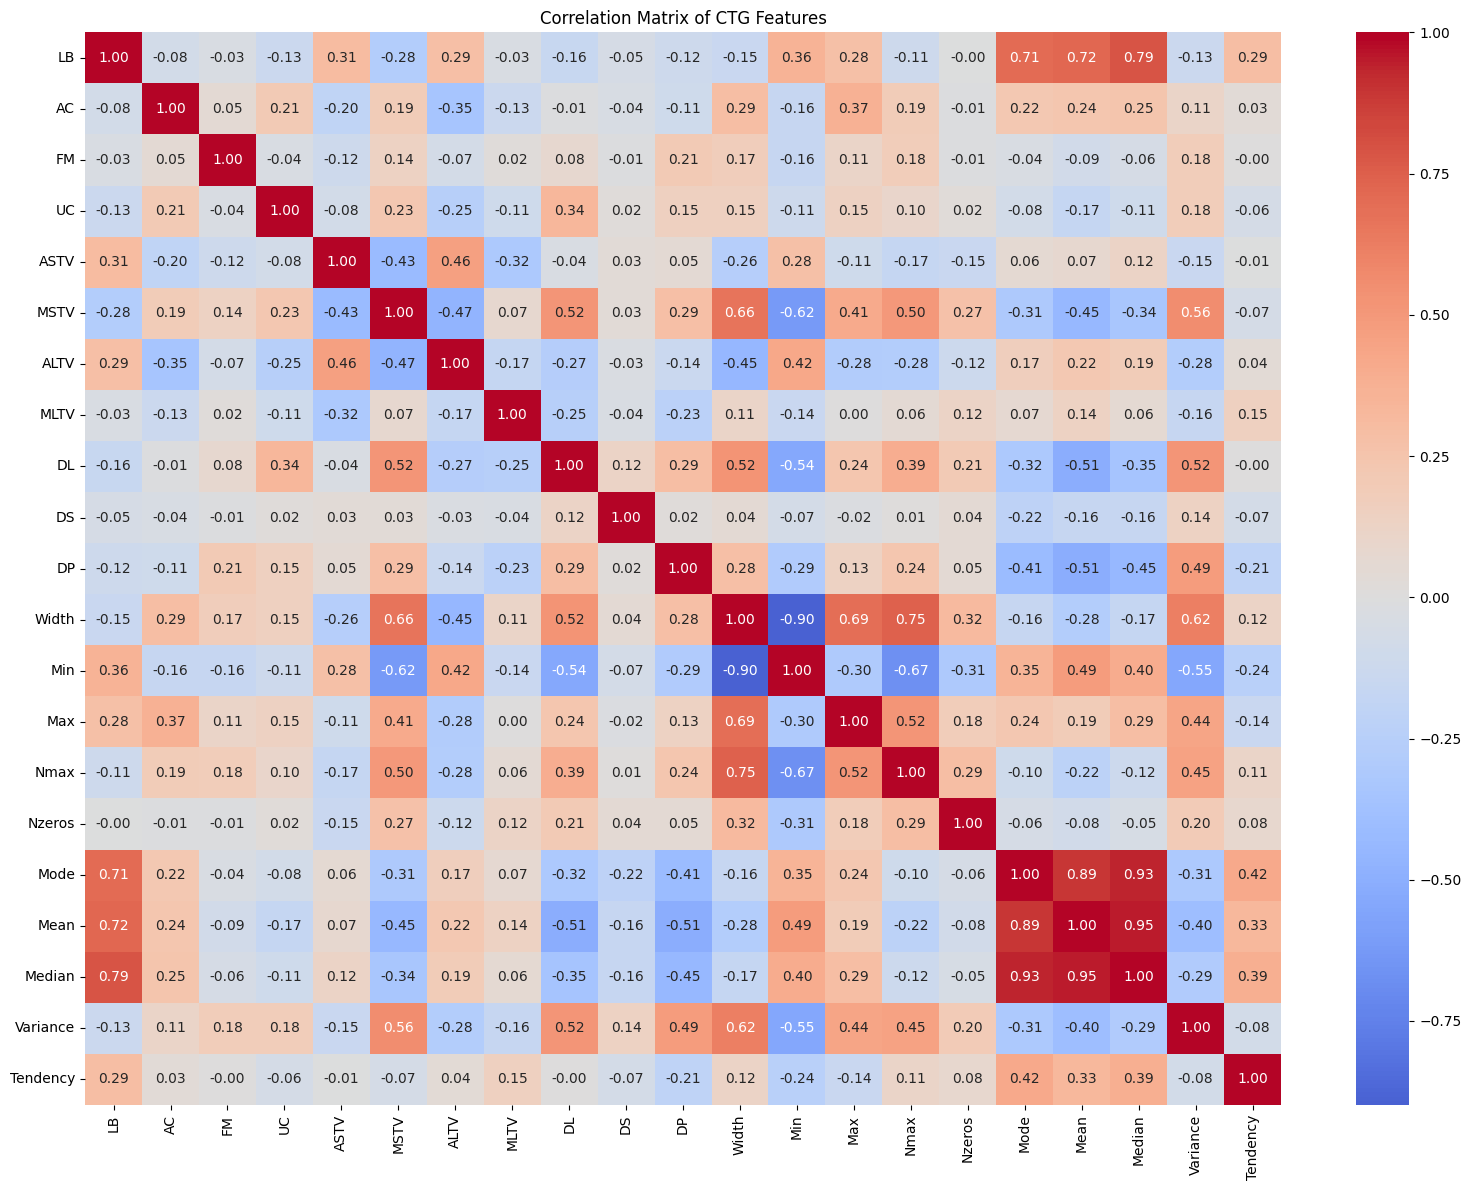

In [17]:
correlation_matrix = X.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of CTG Features")
plt.tight_layout()
plt.show()

In [18]:
corr_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

print(corr_pairs.head(15))

Mean   Median      0.948251
Mode   Median      0.933399
Width  Min        -0.898519
Mode   Mean        0.893412
LB     Median      0.789246
Width  Nmax        0.747071
LB     Mean        0.723121
       Mode        0.708993
Width  Max         0.690769
Min    Nmax       -0.670287
MSTV   Width       0.660847
       Min        -0.622569
Width  Variance    0.615884
MSTV   Variance    0.555852
Min    Variance   -0.545091
dtype: float64


## Correlation Analysis

The correlation matrix was used to examine relationships among the CTG
features.

Several strong correlations were observed. The strongest positive
correlations were between Mean and Median (0.95), Mode and Median (0.93),
and Mode and Mean (0.89). Width and Min showed a strong negative
correlation (-0.90).

These relationships indicate that some CTG variables contain related
information. However, correlated features were not removed solely on the
basis of correlation because correlation does not necessarily imply that
one feature is unnecessary for prediction.

Feature selection will be considered later based on statistical analysis
and model performance.

## IQR ANALYSIS

In [19]:
outlier_summary = []

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df.sort_values(
    "Outlier Count",
    ascending=False
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
15,Nzeros,0.0,0.0,0.0,0.0,0.0,502
2,FM,0.0,2.0,2.0,-3.0,5.0,310
6,ALTV,0.0,11.0,11.0,-16.5,27.5,309
19,Variance,2.0,24.0,22.0,-31.0,57.0,184
10,DP,0.0,0.0,0.0,0.0,0.0,178
1,AC,0.0,4.0,4.0,-6.0,10.0,83
8,DL,0.0,3.0,3.0,-4.5,7.5,81
16,Mode,129.0,148.0,19.0,100.5,176.5,73
7,MLTV,4.6,10.8,6.2,-4.7,20.1,71
5,MSTV,0.7,1.7,1.0,-0.8,3.2,70


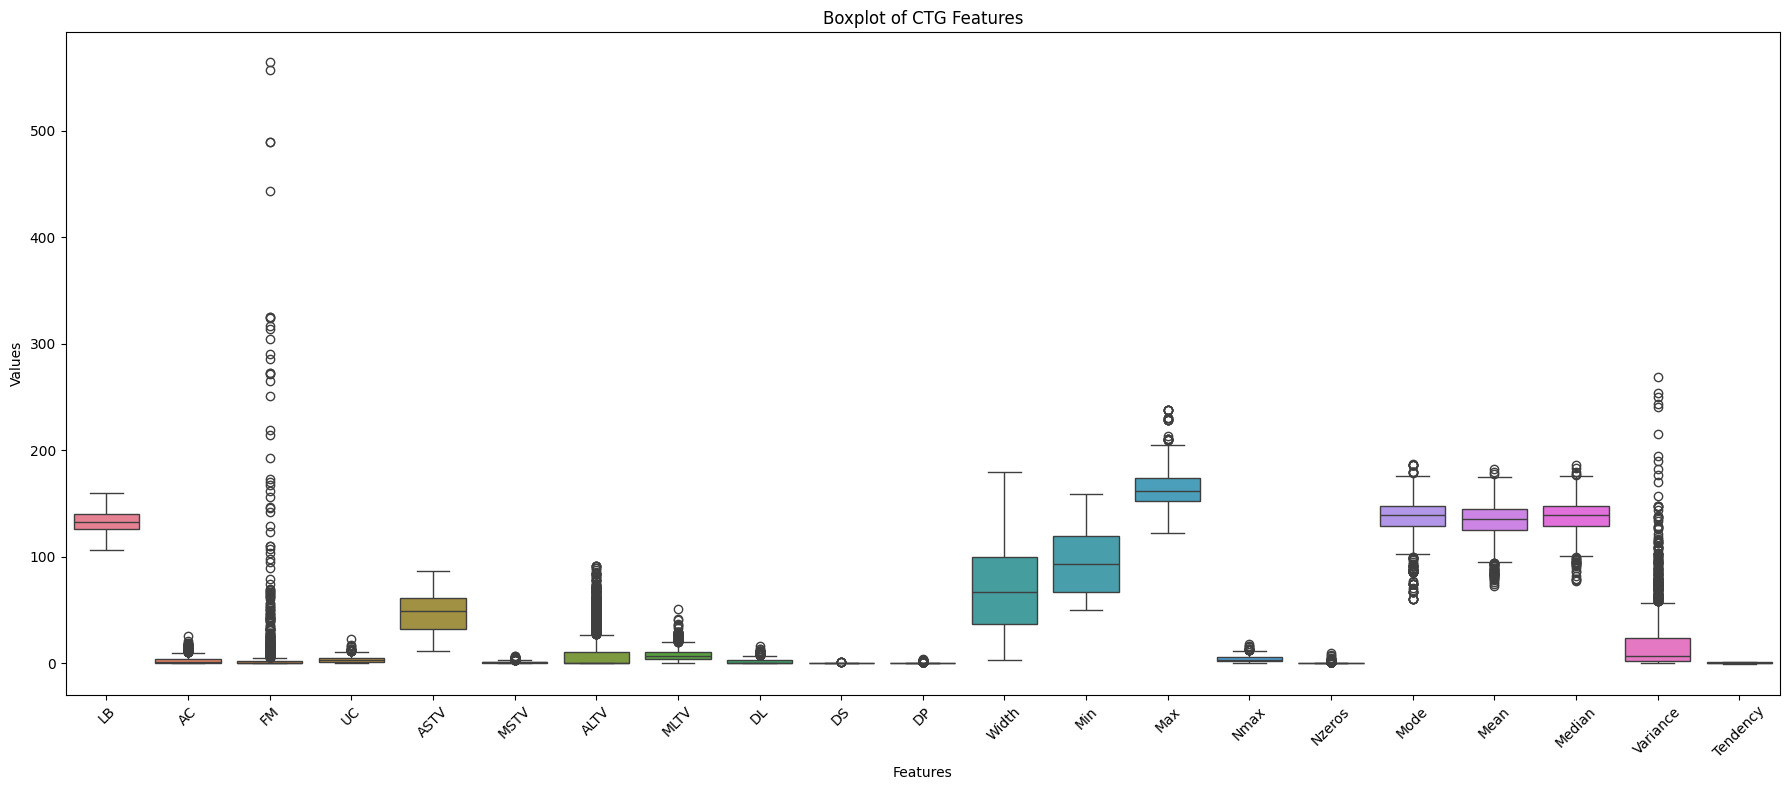

In [20]:
plt.figure(figsize=(18, 8))

sns.boxplot(data=X)

plt.title("Boxplot of CTG Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential
statistical outliers in the CTG features.

Several features, including Nzeros, FM, ALTV, Variance, DP, AC and DL,
contained observations outside the IQR-based bounds. Some variables such
as Nzeros, DP and DS have highly concentrated distributions around zero,
resulting in an IQR of zero or a very small IQR. Consequently, many
non-zero observations are flagged as statistical outliers.

These observations were not removed because an IQR outlier does not
necessarily represent an invalid measurement. In a medical classification
dataset, unusual observations may contain useful information for
distinguishing between fetal state classes.

Therefore, the identified observations are retained for subsequent
analysis and model training.

In [21]:
class_names = {
    1: "Normal",
    2: "Suspect",
    3: "Pathologic"
}

df["NSP_Label"] = df["NSP"].map(class_names)

In [22]:
df[["NSP", "NSP_Label"]].head()

,NSP,NSP_Label
1,2.0,Suspect
2,1.0,Normal
3,1.0,Normal
4,1.0,Normal
5,1.0,Normal


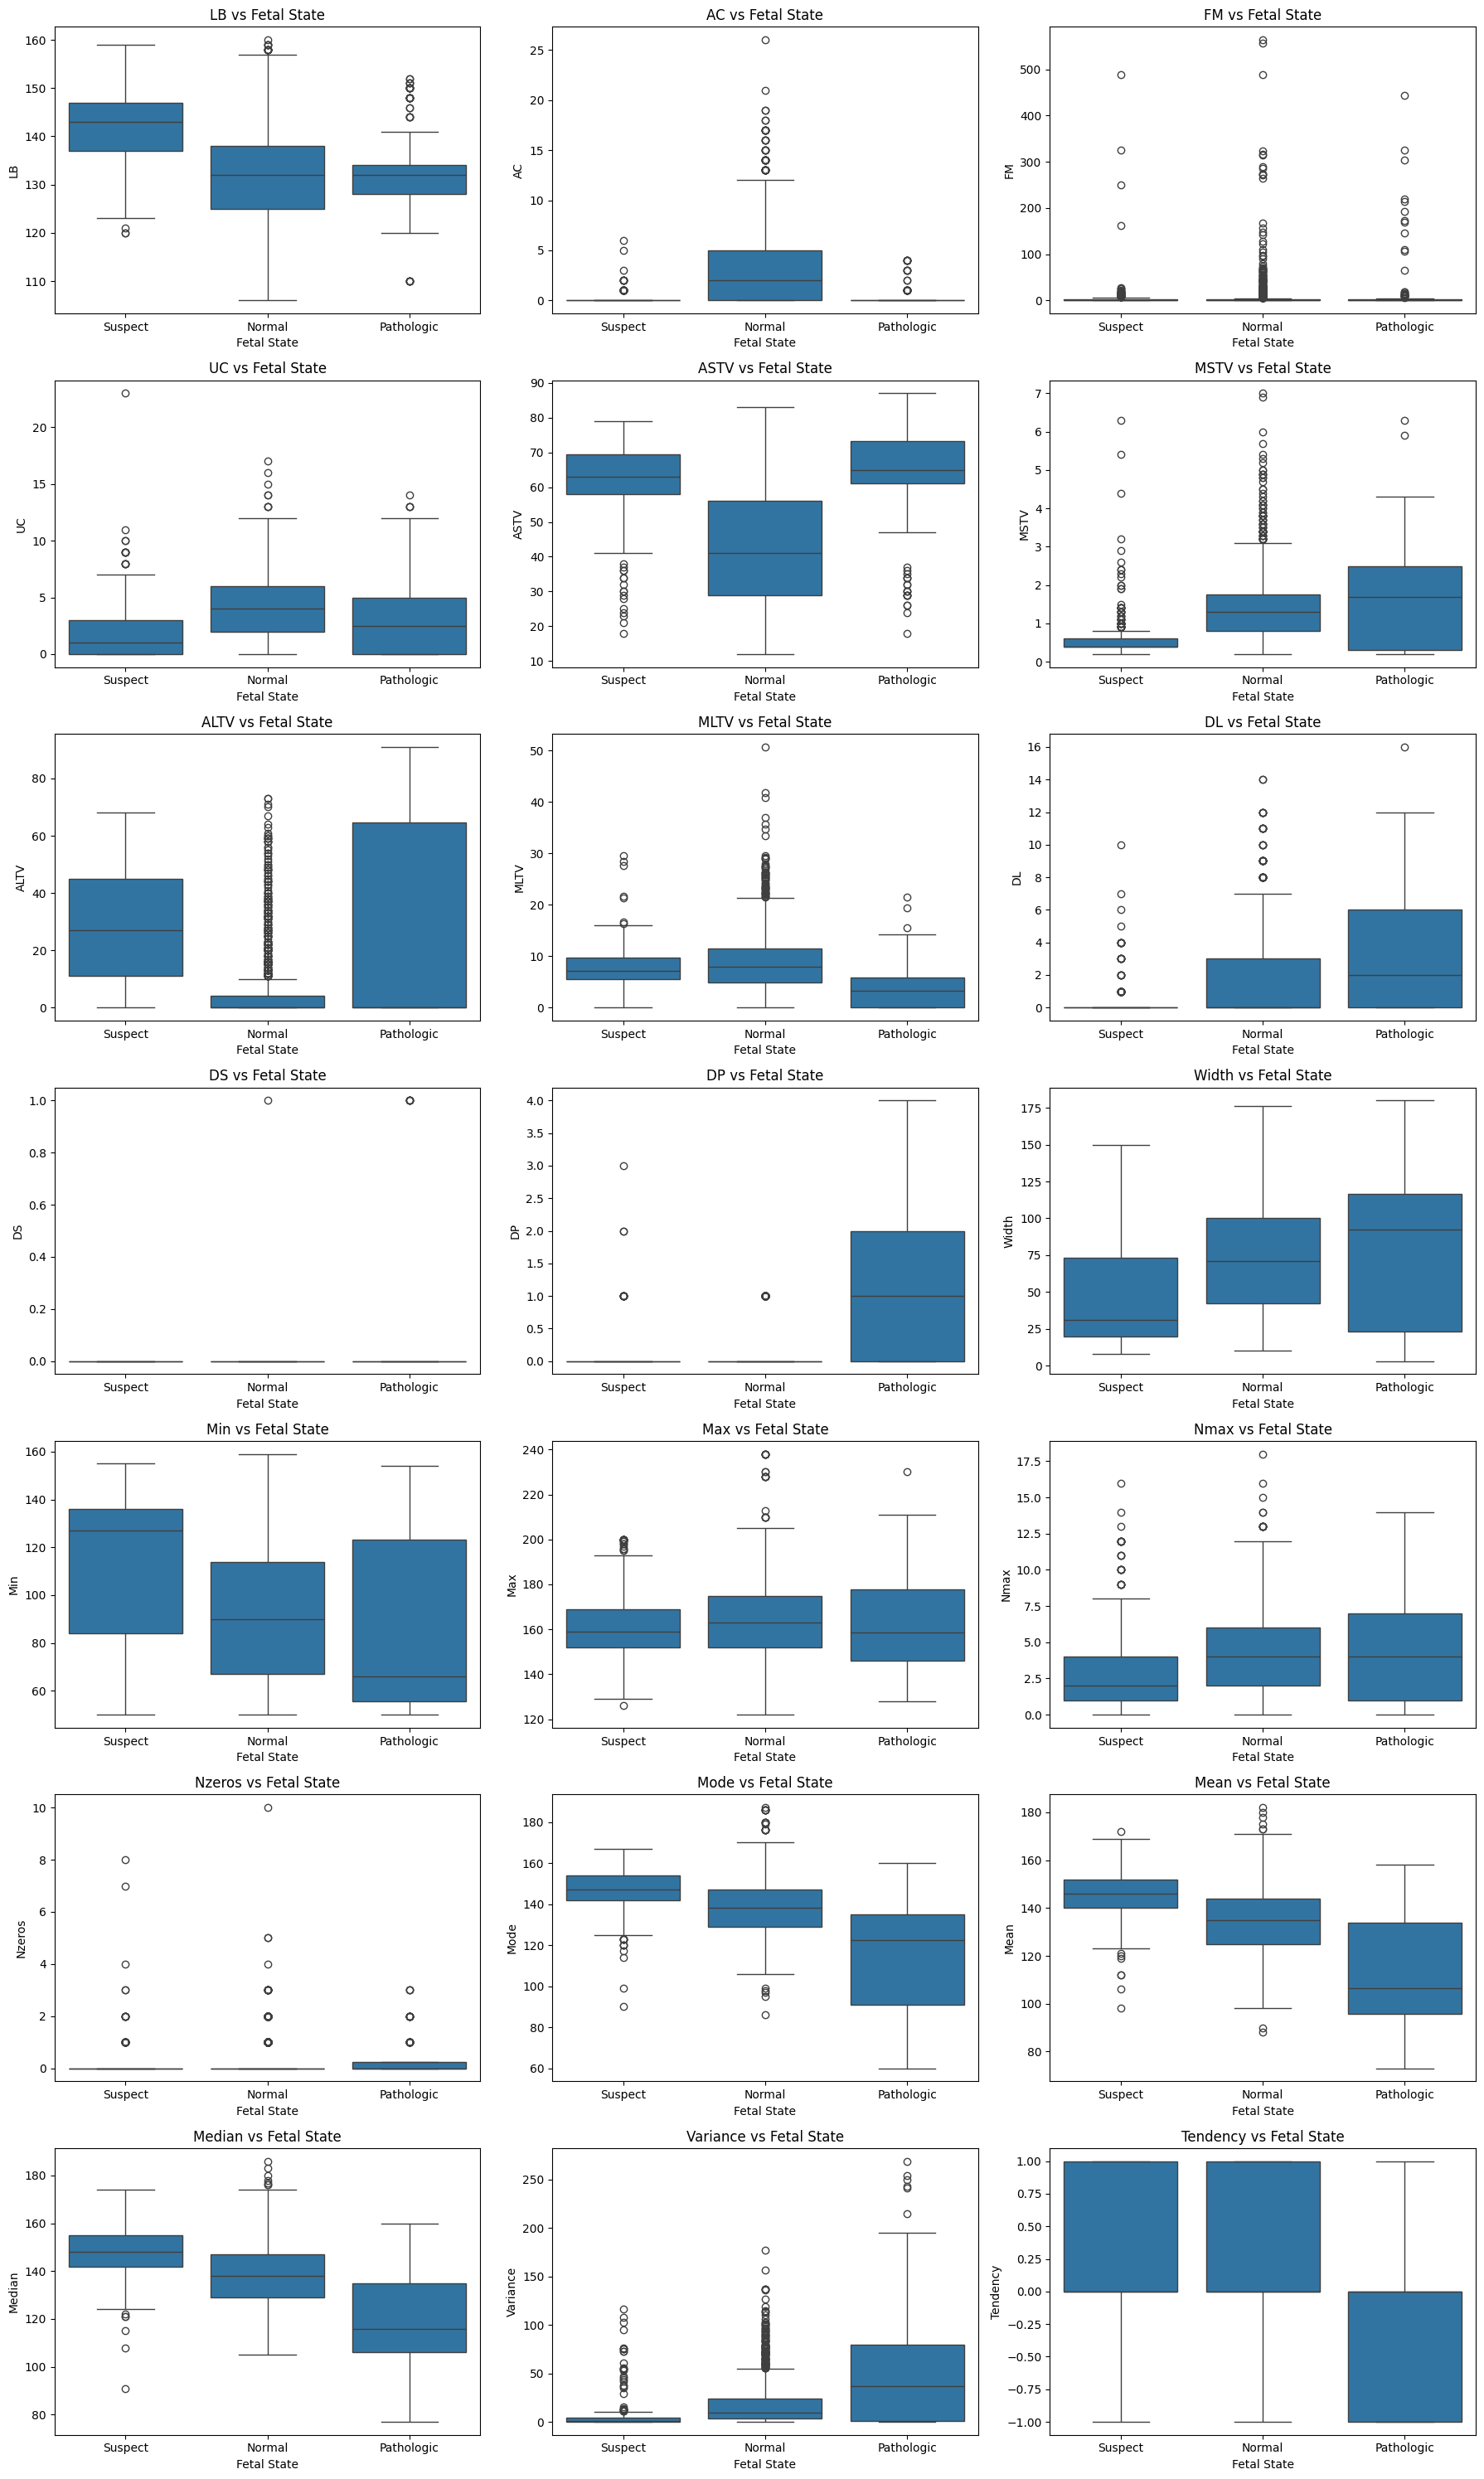

In [23]:
fig, axes = plt.subplots(
    7, 3,
    figsize=(18, 30)
)

axes = axes.flatten()

for i, feature in enumerate(feature_columns):
    sns.boxplot(
        data=df,
        x="NSP_Label",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Fetal State")
    axes[i].set_xlabel("Fetal State")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

In [24]:
class_means = df.groupby("NSP")[feature_columns].mean().T

class_means.columns = [
    "Normal",
    "Suspect",
    "Pathologic"
]

class_means

,Normal,Suspect,Pathologic
LB,131.981873,141.684746,131.687500
AC,3.424169,0.213559,0.329545
FM,6.370997,7.088136,15.681818
UC,3.984290,2.077966,3.261364
ASTV,42.465861,61.901695,64.539773
MSTV,1.430634,0.638983,1.575568
ALTV,5.044713,29.030508,22.846591
MLTV,8.705498,8.026102,3.588636
DL,1.609668,0.403390,3.153409
DS,0.000604,0.000000,0.034091


In [25]:
class_medians = df.groupby("NSP")[feature_columns].median().T

class_medians.columns = [
    "Normal",
    "Suspect",
    "Pathologic"
]

class_medians

,Normal,Suspect,Pathologic
LB,132.0,143.0,132.00
AC,2.0,0.0,0.00
FM,0.0,0.0,1.00
UC,4.0,1.0,2.50
ASTV,41.0,63.0,65.00
MSTV,1.3,0.4,1.70
ALTV,0.0,27.0,0.00
MLTV,8.0,7.1,3.25
DL,0.0,0.0,2.00
DS,0.0,0.0,0.00


## Feature–Target Relationship Analysis

Boxplots and class-wise summary statistics were used to investigate the
relationship between CTG features and the target variable `NSP`.

Several features showed noticeable differences among the Normal, Suspect,
and Pathologic classes. In particular, ASTV, ALTV, Width, Min, Mode, Mean,
Median, and Variance exhibited substantial differences in their distributions
or central tendencies across the three classes.

For example, the mean Variance values were approximately 17.48 for Normal,
7.21 for Suspect, and 50.73 for Pathologic observations. Similarly, the mean
values of Mode, Mean, and Median showed substantial differences among the
classes.

These observations suggest that the CTG measurements contain useful
predictive information for classification. However, individual feature
relationships do not determine the final model performance because the
classification algorithms use combinations of features.

In [26]:
X = df[feature_columns]
y = df["NSP"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1700, 21)
X_test shape: (426, 21)
y_train shape: (1700,)
y_test shape: (426,)


In [27]:
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training class distribution:
NSP
1    1323
2     236
3     141
Name: count, dtype: int64

Testing class distribution:
NSP
1    332
2     59
3     35
Name: count, dtype: int64


In [28]:
print("Training class percentages:")
print(
    (y_train.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTesting class percentages:")
print(
    (y_test.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Training class percentages:
NSP
1    77.82
2    13.88
3     8.29
Name: proportion, dtype: float64

Testing class percentages:
NSP
1    77.93
2    13.85
3     8.22
Name: proportion, dtype: float64


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (1700, 21)
X_test_scaled shape: (426, 21)


## Logistic Regression

In [30]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_train_pred_logistic = logistic_model.predict(X_train_scaled)
y_test_pred_logistic = logistic_model.predict(X_test_scaled)

In [31]:
accuracy_logistic = accuracy_score(
    y_test,
    y_test_pred_logistic
)

precision_logistic = precision_score(
    y_test,
    y_test_pred_logistic,
    average="macro"
)

recall_logistic = recall_score(
    y_test,
    y_test_pred_logistic,
    average="macro"
)

f1_logistic = f1_score(
    y_test,
    y_test_pred_logistic,
    average="macro"
)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy : {accuracy_logistic:.4f}")
print(f"Precision: {precision_logistic:.4f}")
print(f"Recall   : {recall_logistic:.4f}")
print(f"F1-score : {f1_logistic:.4f}")

Logistic Regression Results
---------------------------
Accuracy : 0.8850
Precision: 0.8025
Recall   : 0.7603
F1-score : 0.7767


In [32]:
print(
    classification_report(
        y_test,
        y_test_pred_logistic,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.94      0.95      0.94       332
     Suspect       0.62      0.68      0.65        59
  Pathologic       0.85      0.66      0.74        35

    accuracy                           0.88       426
   macro avg       0.80      0.76      0.78       426
weighted avg       0.89      0.88      0.89       426



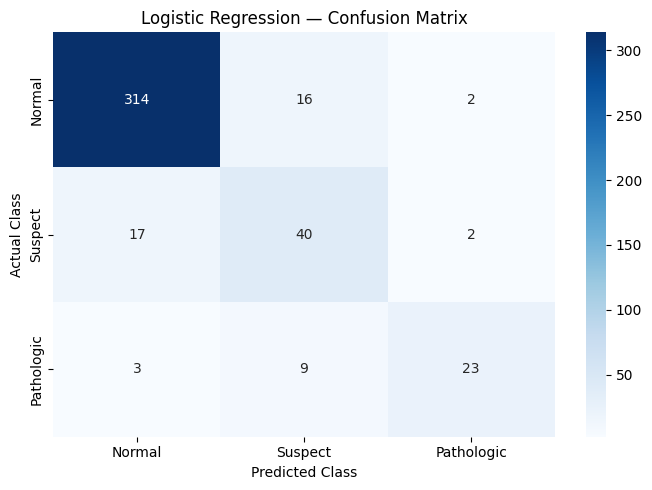

In [33]:
cm_logistic = confusion_matrix(
    y_test,
    y_test_pred_logistic
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [34]:
train_accuracy_logistic = accuracy_score(
    y_train,
    y_train_pred_logistic
)

test_accuracy_logistic = accuracy_score(
    y_test,
    y_test_pred_logistic
)

print(f"Training Accuracy: {train_accuracy_logistic:.4f}")
print(f"Testing Accuracy : {test_accuracy_logistic:.4f}")

Training Accuracy: 0.9071
Testing Accuracy : 0.8850


In [35]:
from sklearn.metrics import roc_auc_score

# ROC-AUC (One-vs-Rest, weighted average) — Logistic Regression
roc_auc_logistic = roc_auc_score(
    y_test,
    logistic_model.predict_proba(X_test_scaled),
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC (OvR, weighted) — Logistic Regression: "
      f"{roc_auc_logistic:.4f}")


ROC-AUC (OvR, weighted) — Logistic Regression: 0.9646


## Logistic Regression — Results and Interpretation

Logistic Regression was used as a baseline multiclass classification model.
The model achieved a test accuracy of 88.50%, with a macro precision of
80.25%, macro recall of 76.03%, and macro F1-score of 77.67%.

The model performed best on the Normal class, achieving a precision of 0.94,
recall of 0.95, and F1-score of 0.94. The Suspect class had lower performance,
with precision of 0.62, recall of 0.68, and F1-score of 0.65. The Pathologic
class achieved precision of 0.85, recall of 0.66, and F1-score of 0.74.

The confusion matrix shows that most Normal observations were correctly
classified. However, some Suspect and Pathologic observations were confused
with other classes. This is consistent with the class imbalance in the
dataset.

The training accuracy was 90.71%, compared with a testing accuracy of 88.50%,
giving a difference of approximately 2.21 percentage points. This indicates
that there is no large training-to-testing accuracy gap for the baseline
Logistic Regression model.

## Gaussian Naive Bayes Classifier

### Conditional Independence Assumption

Gaussian Naive Bayes is a probabilistic classifier based on Bayes' theorem
with a **strong (naive) assumption of conditional independence** between
every pair of features given the class label:

$$P(x_1, x_2, \ldots, x_n \mid y) = \prod_{i=1}^{n} P(x_i \mid y)$$

The 'Gaussian' variant further assumes that the likelihood of each feature
given the class follows a **normal distribution**:

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\!\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

The class mean $\mu_y$ and variance $\sigma_y^2$ are estimated from the
training data for every feature–class combination.

**Why use it?**  
Despite the naive independence assumption (rarely true in practice), GNB
often performs well on real datasets and is extremely fast to train — making
it a strong baseline classifier, especially useful when features have low
pairwise correlation.

**Limitation on CTG data:**  
Many CTG features are correlated (e.g., ASTV and MSTV both capture short-term
variability). The independence assumption is therefore violated, which may
reduce GNB's discriminative power compared to non-naive models such as
Decision Trees or SVC.

In [36]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(
    X_train,
    y_train
)

y_train_pred_nb = nb_model.predict(X_train)
y_test_pred_nb = nb_model.predict(X_test)
    

In [37]:
accuracy_nb = accuracy_score(
    y_test,
    y_test_pred_nb
)

precision_nb = precision_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

recall_nb = recall_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

f1_nb = f1_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

print("Gaussian Naive Bayes Results")
print("----------------------------")
print(f"Accuracy : {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print(f"Recall   : {recall_nb:.4f}")
print(f"F1-score : {f1_nb:.4f}")

Gaussian Naive Bayes Results
----------------------------
Accuracy : 0.8146
Precision: 0.6594
Recall   : 0.7247
F1-score : 0.6737


In [38]:
print(
    classification_report(
        y_test,
        y_test_pred_nb,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.98      0.85      0.91       332
     Suspect       0.46      0.81      0.59        59
  Pathologic       0.55      0.51      0.53        35

    accuracy                           0.81       426
   macro avg       0.66      0.72      0.67       426
weighted avg       0.87      0.81      0.83       426



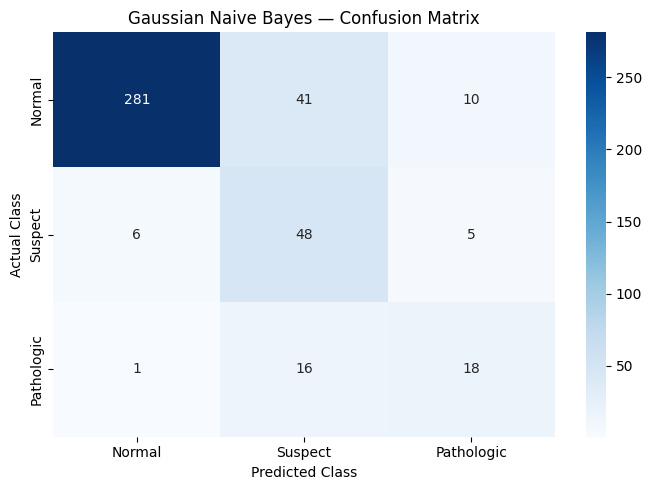

In [39]:
cm_nb = confusion_matrix(
    y_test,
    y_test_pred_nb
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("Gaussian Naive Bayes — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [40]:
train_accuracy_nb = accuracy_score(
    y_train,
    y_train_pred_nb
)

test_accuracy_nb = accuracy_score(
    y_test,
    y_test_pred_nb
)

print(f"Training Accuracy: {train_accuracy_nb:.4f}")
print(f"Testing Accuracy : {test_accuracy_nb:.4f}")

Training Accuracy: 0.8241
Testing Accuracy : 0.8146


In [41]:
from sklearn.metrics import roc_auc_score

# ROC-AUC (One-vs-Rest, weighted average) — Gaussian Naive Bayes
roc_auc_nb = roc_auc_score(
    y_test,
    nb_model.predict_proba(X_test),
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC (OvR, weighted) — Gaussian Naive Bayes: "
      f"{roc_auc_nb:.4f}")


ROC-AUC (OvR, weighted) — Gaussian Naive Bayes: 0.9288


## Gaussian Naive Bayes — Results and Interpretation

Gaussian Naive Bayes was trained directly on the unscaled training set.
Unlike distance-based models (KNN, SVC), GNB does not require feature
standardisation because it models per-class feature distributions
independently.

**Performance observations:**
- GNB tends to perform well on the **Normal** class, which dominates the
  dataset (~78 %), but may underperform on minority classes (Suspect,
  Pathologic) where the independence assumption is most violated.
- A lower macro F1-score (compared to Decision Tree or SVC) is expected
  given the correlated nature of CTG features.
- The **ROC-AUC (OvR, weighted)** score is a more informative metric here
  than accuracy due to class imbalance.

**Conditional independence check:**  
The correlation heatmap (EDA section) confirmed moderate-to-high correlations
among several CTG features, confirming that the conditional independence
assumption is a simplification. Despite this, GNB provides a fast and
interpretable baseline.

## Decision Tree Classifier

In [42]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

y_train_pred_dt = dt_model.predict(X_train)
y_test_pred_dt = dt_model.predict(X_test)

In [43]:
accuracy_dt = accuracy_score(
    y_test,
    y_test_pred_dt
)

precision_dt = precision_score(
    y_test,
    y_test_pred_dt,
    average="macro"
)

recall_dt = recall_score(
    y_test,
    y_test_pred_dt,
    average="macro"
)

f1_dt = f1_score(
    y_test,
    y_test_pred_dt,
    average="macro"
)

print("Decision Tree Classifier Results")
print("--------------------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1-score : {f1_dt:.4f}")

Decision Tree Classifier Results
--------------------------------
Accuracy : 0.9178
Precision: 0.8429
Recall   : 0.8348
F1-score : 0.8379


In [44]:
print(
    classification_report(
        y_test,
        y_test_pred_dt,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.95      0.96      0.96       332
     Suspect       0.79      0.71      0.75        59
  Pathologic       0.78      0.83      0.81        35

    accuracy                           0.92       426
   macro avg       0.84      0.83      0.84       426
weighted avg       0.92      0.92      0.92       426



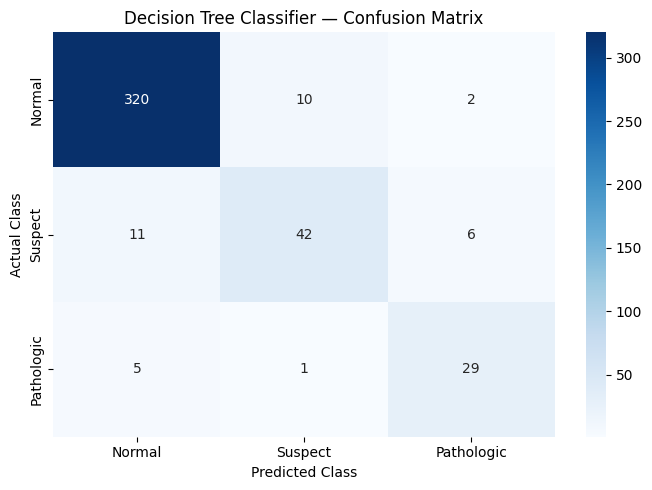

In [45]:
cm_dt = confusion_matrix(
    y_test,
    y_test_pred_dt
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("Decision Tree Classifier — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [46]:
train_accuracy_dt = accuracy_score(
    y_train,
    y_train_pred_dt
)

test_accuracy_dt = accuracy_score(
    y_test,
    y_test_pred_dt
)

print(f"Training Accuracy: {train_accuracy_dt:.4f}")
print(f"Testing Accuracy : {test_accuracy_dt:.4f}")

Training Accuracy: 0.9994
Testing Accuracy : 0.9178


In [47]:
from sklearn.metrics import roc_auc_score

# ROC-AUC (One-vs-Rest, weighted average) — Decision Tree Classifier
roc_auc_dt = roc_auc_score(
    y_test,
    dt_model.predict_proba(X_test),
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC (OvR, weighted) — Decision Tree Classifier: "
      f"{roc_auc_dt:.4f}")


ROC-AUC (OvR, weighted) — Decision Tree Classifier: 0.8897


## Decision Tree Classifier — Results and Interpretation

The baseline Decision Tree Classifier achieved a test accuracy of 91.78%,
macro precision of 84.29%, macro recall of 83.48%, and macro F1-score of
83.79%.

The model achieved strong performance across all three classes. The Normal
class achieved an F1-score of 0.96, while the Suspect and Pathologic classes
achieved F1-scores of 0.75 and 0.81 respectively.

The confusion matrix shows that 320 of 332 Normal observations, 42 of 59
Suspect observations, and 29 of 35 Pathologic observations were correctly
classified.

However, the training accuracy was 99.94%, compared with a testing accuracy
of 91.78%, resulting in an accuracy gap of approximately 8.16 percentage
points. This indicates that the unrestricted decision tree is fitting the
training data very closely and may be overfitting.

Therefore, hyperparameter tuning will be performed to control tree
complexity and improve generalization.

In [48]:
feature_importance_dt = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": dt_model.feature_importances_
})

feature_importance_dt = feature_importance_dt.sort_values(
    "Importance",
    ascending=False
)

feature_importance_dt

,Feature,Importance
5,MSTV,0.269887
17,Mean,0.218655
6,ALTV,0.121772
4,ASTV,0.094514
1,AC,0.057464
0,LB,0.046167
13,Max,0.031574
7,MLTV,0.030399
3,UC,0.025653
10,DP,0.022282


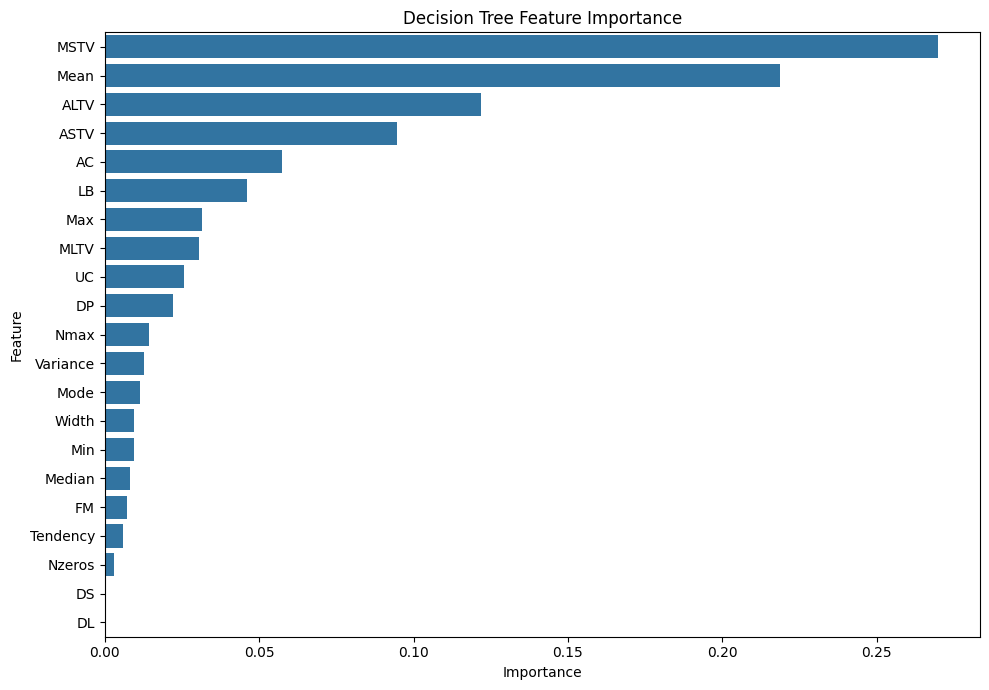

In [49]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_dt,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [50]:
from sklearn.model_selection import GridSearchCV

param_grid_dt = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    param_grid=param_grid_dt,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

dt_grid.fit(
    X_train,
    y_train
)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [51]:
print("Best Parameters:")
print(dt_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(dt_grid.best_score_)

Best Parameters:
{'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 20}

Best Cross-Validation Macro F1:
0.899333899432712


In [52]:
best_dt = dt_grid.best_estimator_

y_train_pred_dt_tuned = best_dt.predict(X_train)
y_test_pred_dt_tuned = best_dt.predict(X_test) 

In [53]:
accuracy_dt_tuned = accuracy_score(
    y_test,
    y_test_pred_dt_tuned
)

precision_dt_tuned = precision_score(
    y_test,
    y_test_pred_dt_tuned,
    average="macro"
)

recall_dt_tuned = recall_score(
    y_test,
    y_test_pred_dt_tuned,
    average="macro"
)

f1_dt_tuned = f1_score(
    y_test,
    y_test_pred_dt_tuned,
    average="macro"
)

print("Tuned Decision Tree Results")
print("---------------------------")
print(f"Accuracy : {accuracy_dt_tuned:.4f}")
print(f"Precision: {precision_dt_tuned:.4f}")
print(f"Recall   : {recall_dt_tuned:.4f}")
print(f"F1-score : {f1_dt_tuned:.4f}")

Tuned Decision Tree Results
---------------------------
Accuracy : 0.9085
Precision: 0.8536
Recall   : 0.8160
F1-score : 0.8323


In [54]:
train_accuracy_dt_tuned = accuracy_score(
    y_train,
    y_train_pred_dt_tuned
)

test_accuracy_dt_tuned = accuracy_score(
    y_test,
    y_test_pred_dt_tuned
)

print(f"Training Accuracy: {train_accuracy_dt_tuned:.4f}")
print(f"Testing Accuracy : {test_accuracy_dt_tuned:.4f}")

Training Accuracy: 0.9565
Testing Accuracy : 0.9085


## Decision Tree Hyperparameter Tuning

GridSearchCV with 5-fold cross-validation was used to tune the Decision Tree
hyperparameters `max_depth`, `min_samples_split`, and `min_samples_leaf`.
Macro F1-score was used as the optimization metric because the dataset has
an imbalanced target distribution.

The best parameter combination was:

- `max_depth = 15`
- `min_samples_split = 20`
- `min_samples_leaf = 2`

The best cross-validation macro F1-score was 0.8993.

The tuned model achieved a test accuracy of 90.85%, macro precision of 85.36%,
macro recall of 81.60%, and macro F1-score of 83.23%.

Compared with the unrestricted tree, training accuracy decreased from 99.94%
to 95.65%, while testing accuracy decreased from 91.78% to 90.85%. The
training-testing accuracy gap therefore decreased from approximately 8.16 to
4.80 percentage points, indicating reduced model complexity and a smaller
generalization gap.

Although the tuned model did not improve the held-out test accuracy or macro
F1-score for this particular split, tuning provided better control over
tree complexity and overfitting.

## KNN 

In [55]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_train_pred_knn = knn_model.predict(X_train_scaled)
y_test_pred_knn = knn_model.predict(X_test_scaled)

In [56]:
accuracy_knn = accuracy_score(
    y_test,
    y_test_pred_knn
)

precision_knn = precision_score(
    y_test,
    y_test_pred_knn,
    average="macro"
)

recall_knn = recall_score(
    y_test,
    y_test_pred_knn,
    average="macro"
)

f1_knn = f1_score(
    y_test,
    y_test_pred_knn,
    average="macro"
)

print("KNN Classifier Results")
print("----------------------")
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")

KNN Classifier Results
----------------------
Accuracy : 0.8826
Precision: 0.8030
Recall   : 0.7214
F1-score : 0.7561


In [57]:
print(
    classification_report(
        y_test,
        y_test_pred_knn,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.91      0.97      0.94       332
     Suspect       0.67      0.51      0.58        59
  Pathologic       0.83      0.69      0.75        35

    accuracy                           0.88       426
   macro avg       0.80      0.72      0.76       426
weighted avg       0.87      0.88      0.88       426



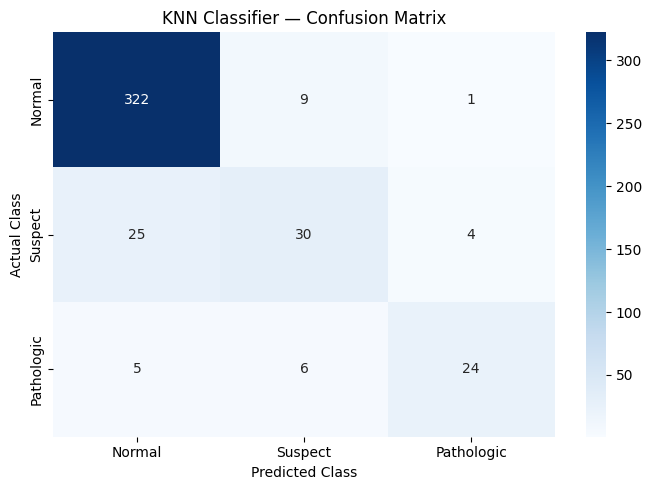

In [58]:
cm_knn = confusion_matrix(
    y_test,
    y_test_pred_knn
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("KNN Classifier — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [59]:
print(
    f"Training Accuracy: "
    f"{accuracy_score(y_train, y_train_pred_knn):.4f}"
)

print(
    f"Testing Accuracy : "
    f"{accuracy_score(y_test, y_test_pred_knn):.4f}"
)

Training Accuracy: 0.9429
Testing Accuracy : 0.8826


In [60]:
from sklearn.metrics import roc_auc_score

# ROC-AUC (One-vs-Rest, weighted average) — KNN Classifier
roc_auc_knn = roc_auc_score(
    y_test,
    knn_model.predict_proba(X_test),
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC (OvR, weighted) — KNN Classifier: "
      f"{roc_auc_knn:.4f}")


ROC-AUC (OvR, weighted) — KNN Classifier: 0.5128


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but KNeighborsClassifier was fitted without feature names
  warnings.warn(


## KNN Classifier — Baseline Results

The K-Nearest Neighbors classifier was trained using standardized features
because KNN is distance-based and is sensitive to differences in feature
scale.

With `k = 5`, the model achieved a test accuracy of 88.26%, macro precision
of 80.30%, macro recall of 72.14%, and macro F1-score of 75.61%.

The model performed strongly on the Normal class, achieving a recall of 0.97.
However, the Suspect class had a recall of only 0.51, with 25 of the 59
Suspect observations incorrectly classified as Normal.

The training accuracy was 94.29% compared with a testing accuracy of 88.26%,
giving a gap of approximately 6.03 percentage points. Therefore,
hyperparameter tuning is performed to investigate whether a different value
of `k` provides better generalization and class-balanced performance.

In [61]:
from sklearn.model_selection import GridSearchCV

param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 20, 25, 30],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 20, 25, 30],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid_knn,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

knn_grid.fit(
    X_train,
    y_train
)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': [3, 5, ...], 'knn__weights': ['uniform', 'distance']}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [62]:
print("Best Parameters:")
print(knn_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(knn_grid.best_score_)

Best Parameters:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}

Best Cross-Validation Macro F1:
0.8467977951910883


In [63]:
best_knn = knn_grid.best_estimator_

y_train_pred_knn_tuned = best_knn.predict(X_train)
y_test_pred_knn_tuned = best_knn.predict(X_test)

In [64]:
accuracy_knn_tuned = accuracy_score(
    y_test,
    y_test_pred_knn_tuned
)

precision_knn_tuned = precision_score(
    y_test,
    y_test_pred_knn_tuned,
    average="macro"
)

recall_knn_tuned = recall_score(
    y_test,
    y_test_pred_knn_tuned,
    average="macro"
)

f1_knn_tuned = f1_score(
    y_test,
    y_test_pred_knn_tuned,
    average="macro"
)

print("Tuned KNN Results")
print("------------------")
print(f"Accuracy : {accuracy_knn_tuned:.4f}")
print(f"Precision: {precision_knn_tuned:.4f}")
print(f"Recall   : {recall_knn_tuned:.4f}")
print(f"F1-score : {f1_knn_tuned:.4f}")

Tuned KNN Results
------------------
Accuracy : 0.9061
Precision: 0.8353
Recall   : 0.8073
F1-score : 0.8206


In [65]:
print(
    classification_report(
        y_test,
        y_test_pred_knn_tuned,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.95      0.96      0.95       332
     Suspect       0.68      0.66      0.67        59
  Pathologic       0.88      0.80      0.84        35

    accuracy                           0.91       426
   macro avg       0.84      0.81      0.82       426
weighted avg       0.90      0.91      0.91       426



In [66]:
print(
    f"Training Accuracy: "
    f"{accuracy_score(y_train, y_train_pred_knn_tuned):.4f}"
)

print(
    f"Testing Accuracy : "
    f"{accuracy_score(y_test, y_test_pred_knn_tuned):.4f}"
)

Training Accuracy: 0.9994
Testing Accuracy : 0.9061


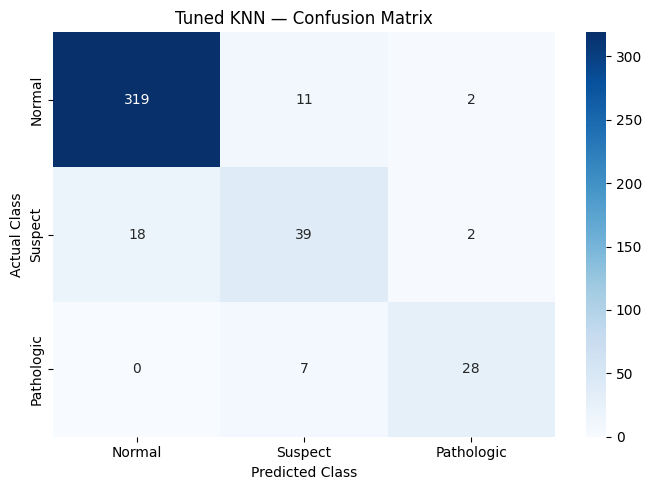

In [67]:
cm_knn_tuned = confusion_matrix(
    y_test,
    y_test_pred_knn_tuned
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("Tuned KNN — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## KNN Hyperparameter Tuning

GridSearchCV with 5-fold cross-validation was used to tune the number of
neighbors, distance metric, and neighbor weighting strategy. Macro F1-score
was used as the optimization metric because the target classes are
imbalanced.

The best configuration was:

- `n_neighbors = 3`
- `weights = "distance"`
- `metric = "manhattan"`

The best cross-validation macro F1-score was 0.8468.

On the held-out test set, the tuned KNN achieved an accuracy of 90.61%,
macro precision of 83.53%, macro recall of 80.73%, and macro F1-score of
82.06%.

Compared with the baseline KNN, macro F1 increased from 75.61% to 82.06%.
Suspect recall improved from 51% to 66%, while Pathologic recall improved
from 69% to 80%.

The tuned model achieved a training accuracy of 99.94% and testing accuracy
of 90.61%, resulting in a 9.33 percentage-point gap. Therefore, although
tuning improved test performance, the model still shows a noticeable
training-testing performance gap.

## SVC - Support Vector Classifier

In [68]:
from sklearn.svm import SVC

svc_model = SVC(
    kernel="rbf",
    random_state=42
)

svc_model.fit(
    X_train_scaled,
    y_train
)

y_train_pred_svc = svc_model.predict(X_train_scaled)
y_test_pred_svc = svc_model.predict(X_test_scaled)

In [69]:
accuracy_svc = accuracy_score(
    y_test,
    y_test_pred_svc
)

precision_svc = precision_score(
    y_test,
    y_test_pred_svc,
    average="macro"
)

recall_svc = recall_score(
    y_test,
    y_test_pred_svc,
    average="macro"
)

f1_svc = f1_score(
    y_test,
    y_test_pred_svc,
    average="macro"
)

print("SVC Results")
print("-----------")
print(f"Accuracy : {accuracy_svc:.4f}")
print(f"Precision: {precision_svc:.4f}")
print(f"Recall   : {recall_svc:.4f}")
print(f"F1-score : {f1_svc:.4f}")

SVC Results
-----------
Accuracy : 0.8967
Precision: 0.8309
Recall   : 0.7506
F1-score : 0.7854


In [70]:
print(
    classification_report(
        y_test,
        y_test_pred_svc,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.93      0.97      0.95       332
     Suspect       0.67      0.59      0.63        59
  Pathologic       0.89      0.69      0.77        35

    accuracy                           0.90       426
   macro avg       0.83      0.75      0.79       426
weighted avg       0.89      0.90      0.89       426



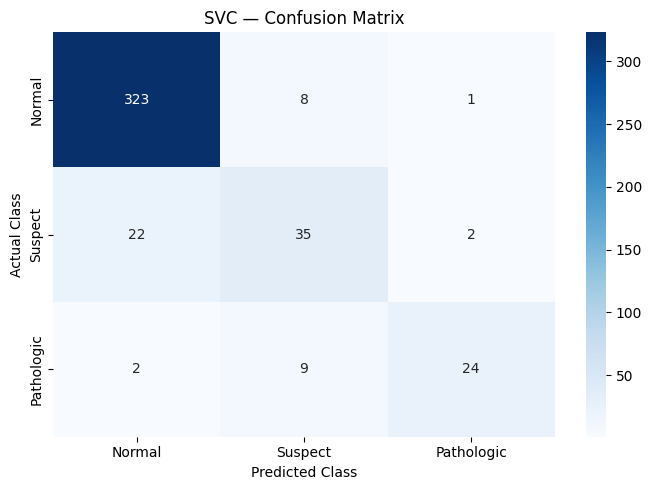

In [71]:
cm_svc = confusion_matrix(
    y_test,
    y_test_pred_svc
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svc,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("SVC — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [72]:
print(
    f"Training Accuracy: "
    f"{accuracy_score(y_train, y_train_pred_svc):.4f}"
)

print(
    f"Testing Accuracy : "
    f"{accuracy_score(y_test, y_test_pred_svc):.4f}"
)

Training Accuracy: 0.9359
Testing Accuracy : 0.8967


In [ ]:
from sklearn.metrics import roc_auc_score
from scipy.special import softmax

# ROC-AUC (One-vs-Rest, weighted) — SVC
#
# SVC(probability=False) has no predict_proba(), so we use
# decision_function() which returns raw signed distances (shape: n_samples x n_classes).
# roc_auc_score with multi_class='ovr' requires probability scores that sum to 1,
# so we apply softmax to convert the decision scores to pseudo-probabilities.
svc_decision_scores = svc_model.decision_function(X_test_scaled)
svc_proba = softmax(svc_decision_scores, axis=1)

roc_auc_svc = roc_auc_score(
    y_test,
    svc_proba,
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC (OvR, weighted) — SVC: "
      f"{roc_auc_svc:.4f}")


## SVC — Baseline Results

The Support Vector Classifier was trained using standardized features because
SVC is sensitive to feature scale. An RBF kernel was used for the baseline
model.

The baseline SVC achieved a test accuracy of 89.67%, macro precision of
83.09%, macro recall of 75.06%, and macro F1-score of 78.54%.

The Normal class achieved an F1-score of 0.95. The Suspect class achieved
precision of 0.67, recall of 0.59, and F1-score of 0.63, while the Pathologic
class achieved precision of 0.89, recall of 0.69, and F1-score of 0.77.

The training accuracy was 93.59%, compared with 89.67% on the testing set,
giving a difference of approximately 3.92 percentage points.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

In [ ]:
param_grid_svc = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1],
    "svc__kernel": ["rbf", "linear"]
}

In [ ]:
svc_grid = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid_svc,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

svc_grid.fit(
    X_train,
    y_train
)

,estimator,"Pipeline(step...svc', SVC())])"
,param_grid,"{'svc__C': [0.1, 1, ...], 'svc__gamma': ['scale', 0.01, ...], 'svc__kernel': ['rbf', 'linear']}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [ ]:
print("Best Parameters:")
print(svc_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(svc_grid.best_score_)

Best Parameters:
{'svc__C': 100, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Best Cross-Validation Macro F1:
0.8772971171869702


In [ ]:
best_svc = svc_grid.best_estimator_

y_train_pred_svc_tuned = best_svc.predict(X_train)
y_test_pred_svc_tuned = best_svc.predict(X_test)

In [ ]:
accuracy_svc_tuned = accuracy_score(
    y_test,
    y_test_pred_svc_tuned
)

precision_svc_tuned = precision_score(
    y_test,
    y_test_pred_svc_tuned,
    average="macro"
)

recall_svc_tuned = recall_score(
    y_test,
    y_test_pred_svc_tuned,
    average="macro"
)

f1_svc_tuned = f1_score(
    y_test,
    y_test_pred_svc_tuned,
    average="macro"
)

print("Tuned SVC Results")
print("-----------------")
print(f"Accuracy : {accuracy_svc_tuned:.4f}")
print(f"Precision: {precision_svc_tuned:.4f}")
print(f"Recall   : {recall_svc_tuned:.4f}")
print(f"F1-score : {f1_svc_tuned:.4f}")

Tuned SVC Results
-----------------
Accuracy : 0.9225
Precision: 0.8652
Recall   : 0.8406
F1-score : 0.8519


In [ ]:
print(
    classification_report(
        y_test,
        y_test_pred_svc_tuned,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.95      0.97      0.96       332
     Suspect       0.79      0.69      0.74        59
  Pathologic       0.86      0.86      0.86        35

    accuracy                           0.92       426
   macro avg       0.87      0.84      0.85       426
weighted avg       0.92      0.92      0.92       426



In [ ]:
print(
    f"Training Accuracy: "
    f"{accuracy_score(y_train, y_train_pred_svc_tuned):.4f}"
)

print(
    f"Testing Accuracy : "
    f"{accuracy_score(y_test, y_test_pred_svc_tuned):.4f}"
)

Training Accuracy: 0.9888
Testing Accuracy : 0.9225


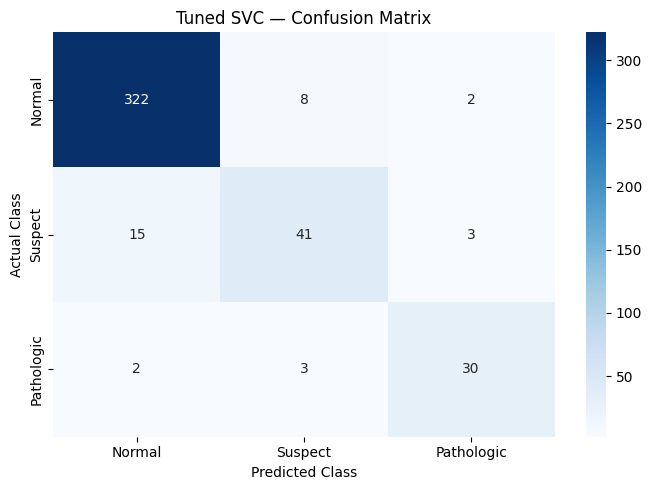

In [ ]:
cm_svc_tuned = confusion_matrix(
    y_test,
    y_test_pred_svc_tuned
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svc_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathologic"],
    yticklabels=["Normal", "Suspect", "Pathologic"]
)

plt.title("Tuned SVC — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## SVC Hyperparameter Tuning

GridSearchCV with 5-fold cross-validation was used to tune the SVC
hyperparameters `C`, `gamma`, and `kernel`. Macro F1-score was selected as
the optimization metric because the target classes are imbalanced.

The best configuration was:

- `C = 100`
- `gamma = "scale"`
- `kernel = "rbf"`

The best cross-validation macro F1-score was 0.8773.

The tuned SVC achieved a test accuracy of 92.25%, macro precision of 86.52%,
macro recall of 84.06%, and macro F1-score of 85.19%.

The Normal class achieved an F1-score of 0.96, while the Suspect and
Pathologic classes achieved F1-scores of 0.74 and 0.86 respectively.

Compared with the baseline SVC, macro F1 improved from 78.54% to 85.19%.
Pathologic recall also improved from 69% to 86%.

The tuned model achieved a training accuracy of 98.88% and testing accuracy
of 92.25%, resulting in a 6.63 percentage-point difference between training
and testing accuracy.

## Part A — Classification Comparison Table

The table below consolidates the performance of all five Part A
classifiers on the held-out test set.

Metrics reported:
- **Accuracy** — overall fraction of correct predictions
- **Precision** — macro-averaged; penalises false positives per class
- **Recall** — macro-averaged; penalises false negatives per class
- **F1-Score** — macro-averaged harmonic mean of Precision and Recall
- **ROC-AUC** — weighted One-vs-Rest AUC; robust to class imbalance

All models were evaluated on the **same 20 % held-out test split**
(`random_state=42`) to ensure fair comparison.

In [ ]:
classification_results_partA = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Gaussian Naive Bayes",
        "Decision Tree",
        "KNN",
        "SVC"
    ],
    "Accuracy": [
        round(accuracy_logistic, 4),
        round(accuracy_nb,       4),
        round(accuracy_dt,       4),
        round(accuracy_knn,      4),
        round(accuracy_svc,      4)
    ],
    "Precision (macro)": [
        round(precision_logistic, 4),
        round(precision_nb,       4),
        round(precision_dt,       4),
        round(precision_knn,      4),
        round(precision_svc,      4)
    ],
    "Recall (macro)": [
        round(recall_logistic, 4),
        round(recall_nb,       4),
        round(recall_dt,       4),
        round(recall_knn,      4),
        round(recall_svc,      4)
    ],
    "F1-Score (macro)": [
        round(f1_logistic, 4),
        round(f1_nb,       4),
        round(f1_dt,       4),
        round(f1_knn,      4),
        round(f1_svc,      4)
    ],
    "ROC-AUC (OvR weighted)": [
        round(roc_auc_logistic, 4),
        round(roc_auc_nb,       4),
        round(roc_auc_dt,       4),
        round(roc_auc_knn,      4),
        round(roc_auc_svc,      4)
    ]
})

classification_results_partA


### Part A — Key Observations

The comparison table above summarises performance across all five
Part A classifiers on the CTG dataset.

ROC-AUC (One-vs-Rest, weighted average) is used as the primary
discrimination metric because it is robust to the class imbalance
present in the dataset (Normal ≈ 78 %, Suspect ≈ 14 %, Pathologic ≈ 8 %).

A full 10-algorithm consolidated table (including Part B models:
Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP) will be
presented in Review 2.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

y_train_pred_gb = gb_model.predict(X_train)
y_test_pred_gb = gb_model.predict(X_test)

In [ ]:
accuracy_gb = accuracy_score(
    y_test,
    y_test_pred_gb
)

precision_gb = precision_score(
    y_test,
    y_test_pred_gb,
    average="macro"
)

recall_gb = recall_score(
    y_test,
    y_test_pred_gb,
    average="macro"
)

f1_gb = f1_score(
    y_test,
    y_test_pred_gb,
    average="macro"
)

print("Gradient Boosting Classifier Results")
print("------------------------------------")
print(f"Accuracy : {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall   : {recall_gb:.4f}")
print(f"F1-score : {f1_gb:.4f}")

Gradient Boosting Classifier Results
------------------------------------
Accuracy : 0.9460
Precision: 0.9153
Recall   : 0.8817
F1-score : 0.8960


In [ ]:
print(
    classification_report(
        y_test,
        y_test_pred_gb,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.96      0.98      0.97       332
     Suspect       0.90      0.75      0.81        59
  Pathologic       0.89      0.91      0.90        35

    accuracy                           0.95       426
   macro avg       0.92      0.88      0.90       426
weighted avg       0.94      0.95      0.94       426



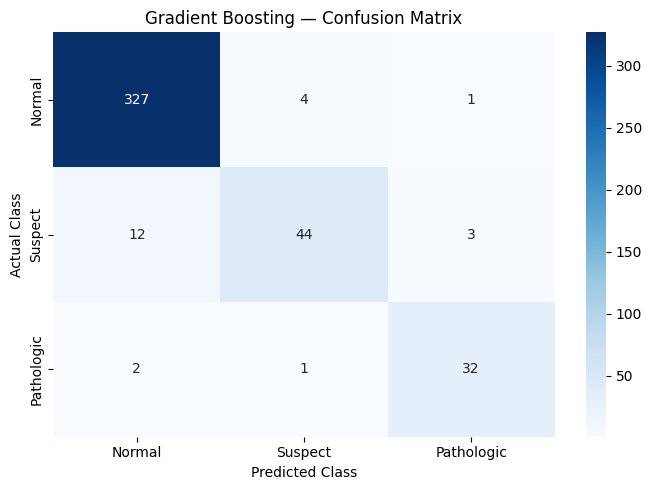

In [ ]:
cm_gb = confusion_matrix(
    y_test,
    y_test_pred_gb
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("Gradient Boosting — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [ ]:
print(
    f"Training Accuracy: "
    f"{accuracy_score(y_train, y_train_pred_gb):.4f}"
)

print(
    f"Testing Accuracy : "
    f"{accuracy_score(y_test, y_test_pred_gb):.4f}"
)

Training Accuracy: 0.9947
Testing Accuracy : 0.9460


## Gradient Boosting Classifier — Baseline Results

The Gradient Boosting Classifier achieved a test accuracy of 94.60%, macro
precision of 91.53%, macro recall of 88.17%, and macro F1-score of 89.60%.

The model achieved strong performance across all three fetal-state classes.
The Normal class achieved an F1-score of 0.97, the Suspect class achieved an
F1-score of 0.81, and the Pathologic class achieved an F1-score of 0.90.

The confusion matrix shows that 327 of 332 Normal observations, 44 of 59
Suspect observations, and 32 of 35 Pathologic observations were correctly
classified.

The training accuracy was 99.47%, while testing accuracy was 94.60%, giving
a difference of approximately 4.87 percentage points. This indicates some
difference between training and testing performance, although the model
maintains strong performance on the held-out test set.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier

param_grid_gb = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingClassifier(
        random_state=42
    ),
    param_grid=param_grid_gb,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

gb_grid.fit(
    X_train,
    y_train
)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'log_loss'


In [ ]:
print("Best Parameters:")
print(gb_grid.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(gb_grid.best_score_)

In [ ]:
best_gb = gb_grid.best_estimator_

y_train_pred_gb_tuned = best_gb.predict(X_train)
y_test_pred_gb_tuned = best_gb.predict(X_test)

In [ ]:
best_gb = gb_grid.best_estimator_

y_train_pred_gb_tuned = best_gb.predict(X_train)
y_test_pred_gb_tuned = best_gb.predict(X_test)

In [ ]:
print(
    f"Training Accuracy: "
    f"{accuracy_score(y_train, y_train_pred_gb_tuned):.4f}"
)

print(
    f"Testing Accuracy : "
    f"{accuracy_score(y_test, y_test_pred_gb_tuned):.4f}"
)

In [ ]:
cm_gb_tuned = confusion_matrix(
    y_test,
    y_test_pred_gb_tuned
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_gb_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("Tuned Gradient Boosting — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()